# 01 – Exploration de la consommation électrique belge

Données : Elia, jeu `ods001`, chargé dans `data/elia.db` par `src/ingest.py`.
But : comprendre ce qui fait varier la consommation pour choisir les variables du modèle J+1.

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import holidays

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True

## 1. Chargement

On lit la table SQL, puis on passe de l'UTC à l'heure belge : la consommation suit l'heure locale des gens.

In [2]:
conn = sqlite3.connect("../data/elia.db")
df = pd.read_sql(
    "SELECT datetime_utc, total_load_mw, dayahead_fc_mw FROM load WHERE total_load_mw IS NOT NULL",
    conn,
)
conn.close()

df["datetime"] = pd.to_datetime(df["datetime_utc"], utc=True).dt.tz_convert("Europe/Brussels")
df = df.set_index("datetime").drop(columns="datetime_utc")
df.describe().round(0)

,total_load_mw,dayahead_fc_mw
count,415326.0,415326.0
mean,9551.0,9536.0
std,1394.0,1363.0
min,5877.0,6058.0
25%,8460.0,8468.0
50%,9528.0,9519.0
75%,10576.0,10546.0
max,13815.0,13751.0


## 2. Vue d'ensemble : moyenne journalière sur 11 ans

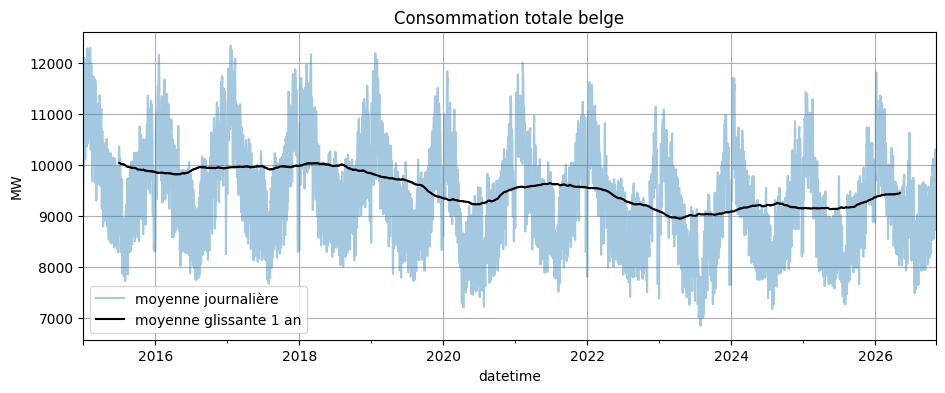

In [3]:
daily = df["total_load_mw"].resample("D").mean()
ax = daily.plot(alpha=0.4, label="moyenne journalière")
daily.rolling(365, center=True).mean().plot(ax=ax, color="black", label="moyenne glissante 1 an")
ax.set_ylabel("MW"); ax.legend(); ax.set_title("Consommation totale belge")
plt.show()

## 3. Cycle annuel : moyenne mensuelle, une courbe par année

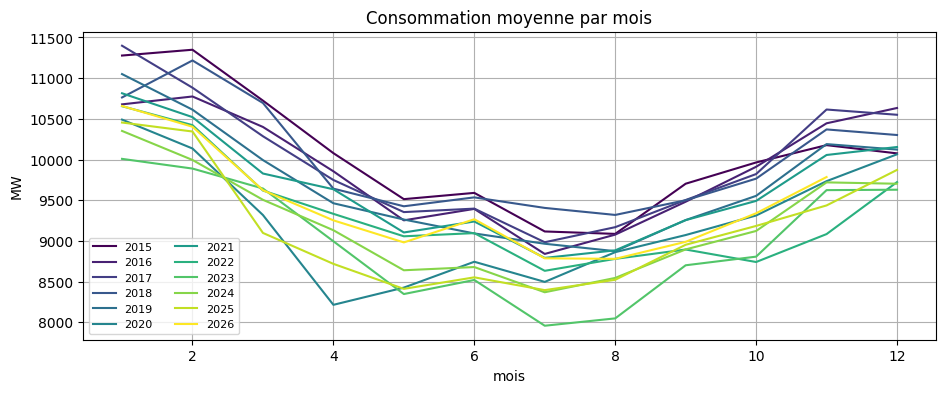

In [4]:
monthly = df["total_load_mw"].groupby([df.index.year, df.index.month]).mean().unstack(0)
ax = monthly.plot(colormap="viridis")
ax.set_xlabel("mois"); ax.set_ylabel("MW"); ax.set_title("Consommation moyenne par mois")
ax.legend(ncol=2, fontsize=8)
plt.show()

## 4. Cycle journalier et hebdomadaire : profil horaire par jour de la semaine

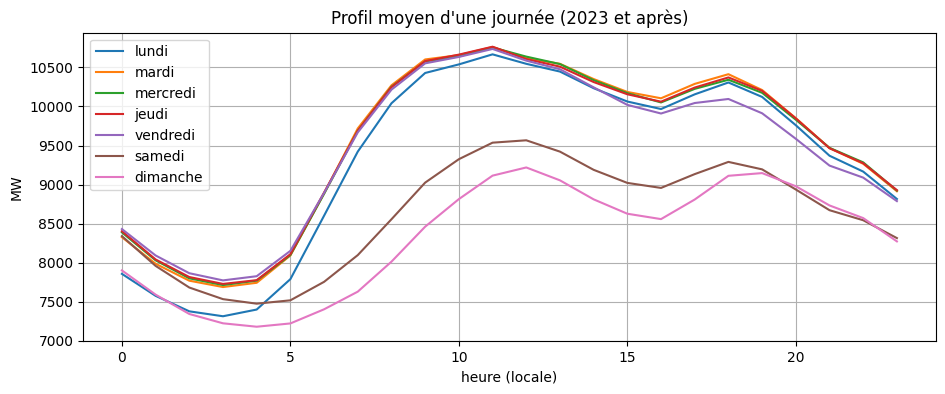

In [5]:
recent = df.loc["2023":]
jours = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]
profile = recent["total_load_mw"].groupby([recent.index.hour, recent.index.dayofweek]).mean().unstack()
profile.columns = jours
ax = profile.plot()
ax.set_xlabel("heure (locale)"); ax.set_ylabel("MW"); ax.set_title("Profil moyen d'une journée (2023 et après)")
plt.show()

## 5. Jours fériés : ressemblent-ils à un dimanche ?

In [6]:
be_holidays = holidays.Belgium(years=range(2015, 2027))
d = daily.to_frame("load")
d["type"] = "semaine"
d.loc[d.index.dayofweek == 5, "type"] = "samedi"
d.loc[d.index.dayofweek == 6, "type"] = "dimanche"
d.loc[[day.date() in be_holidays for day in d.index], "type"] = "férié"
d.loc["2023":].groupby("type")["load"].mean().round(0).sort_values()

type
férié       8034.0
dimanche    8347.0
samedi      8628.0
semaine     9521.0
Name: load, dtype: float64

## 6. Mémoire de la série : corrélation avec le passé

Pour prévoir demain, on ne connaît pas encore aujourd'hui en entier. On regarde donc la corrélation
avec la valeur d'il y a 1 jour, 2 jours et 7 jours, à la même heure.

In [7]:
hourly = df["total_load_mw"].resample("h").mean()
pd.Series({f"{h // 24} j": hourly.autocorr(lag=h) for h in [24, 48, 168]}).round(3)

1 j    0.847
2 j    0.703
7 j    0.904
dtype: float64

## 7. La référence : où la prévision J+1 d'Elia se trompe-t-elle ?

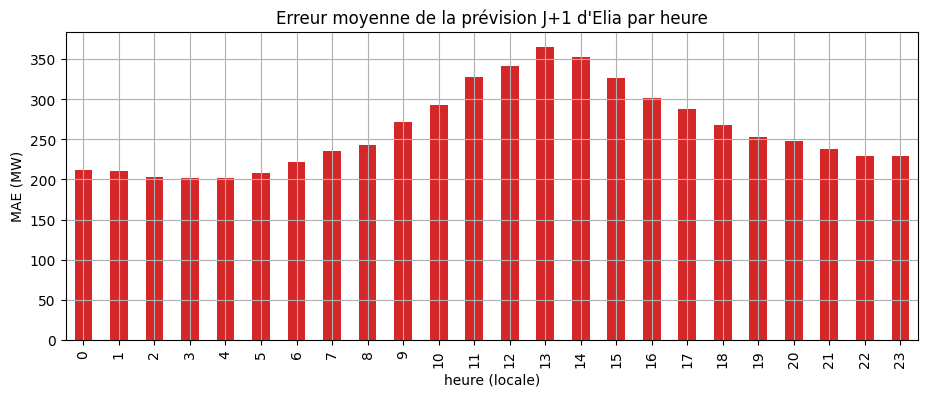

In [8]:
err = (df["total_load_mw"] - df["dayahead_fc_mw"]).abs()
by_hour = err.loc["2023":].groupby(err.loc["2023":].index.hour).mean()
ax = by_hour.plot(kind="bar", color="tab:red")
ax.set_xlabel("heure (locale)"); ax.set_ylabel("MAE (MW)"); ax.set_title("Erreur moyenne de la prévision J+1 d'Elia par heure")
plt.show()